# Praktikum 5 - Evaluasi Trade-off Recall vs Query Time (ANN Benchmark)

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

## Benchmark ANNOY, FAISS IVF, dan HNSW pada 100.000 Vektor Berdimensi 128

Pada praktikum kelima ini saya mengevaluasi kurva kompromi (*trade-off*) antara akurasi pencarian (**Recall@10** terhadap *ground-truth* `faiss.IndexFlatL2`) dan waktu rata-rata pencarian per query (**ms/query**) pada `100.000` vektor database dan `1.000` vektor query berdimensi tinggi (`d = 128`), dengan memvariasikan hyperparameter pencarian masing-masing algoritma:
- **Annoy (`n_trees = 10`):** variasi `search_k` pada `[200, 500, 1000, 2000]`
- **FAISS (`IndexIVFFlat`, `nlist = 100`):** variasi `nprobe` pada `[1, 5, 10, 20]`
- **HNSW (`ef_construction = 200, M = 16`):** variasi `ef` pada `[50, 100, 200, 400]`

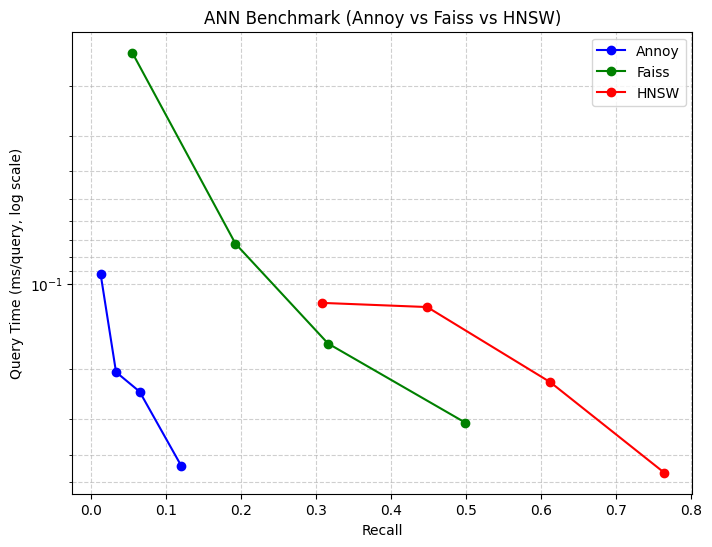

,Algoritma,Parameter,Recall@10,Query Time (ms/query)
0,Annoy,search_k=200,0.0131,0.0923
1,Annoy,search_k=500,0.0336,0.2045
2,Annoy,search_k=1000,0.0650,0.2397
3,Annoy,search_k=2000,0.1206,0.4388
4,FAISS IVF,nprobe=1,0.0553,0.0153
5,FAISS IVF,nprobe=5,0.1927,0.0720
6,FAISS IVF,nprobe=10,0.3161,0.1622
7,FAISS IVF,nprobe=20,0.4987,0.3082
8,HNSW,ef=50,0.3074,0.1165
9,HNSW,ef=100,0.4482,0.1206


In [1]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt
import pandas as pd

# -------------------------------
# Dataset random
# -------------------------------
d = 128        # dimensi
nb = 100000    # jumlah database vector
nq = 1000      # jumlah query

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

# -------------------------------
# Ground truth dengan FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

# -------------------------------
# Fungsi recall
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

# -------------------------------
# Benchmark Annoy
# -------------------------------
def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)

    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark FAISS IVF
# -------------------------------
def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)

    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark HNSW
# -------------------------------
def run_hnsw(xb, xq, ef=100, M=16, k=10):
    num_elements = xb.shape[0]
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
    p.add_items(xb)
    p.set_ef(ef)

    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Jalankan benchmark dengan beberapa parameter
# -------------------------------
results = {"Annoy": [], "Faiss": [], "HNSW": []}
summary_rows = []

# Annoy
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
    results["Annoy"].append((rec, t))
    summary_rows.append({'Algoritma': 'Annoy', 'Parameter': f'search_k={sk}', 'Recall@10': round(rec, 4), 'Query Time (ms/query)': round(t, 4)})

# FAISS
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
    results["Faiss"].append((rec, t))
    summary_rows.append({'Algoritma': 'FAISS IVF', 'Parameter': f'nprobe={npb}', 'Recall@10': round(rec, 4), 'Query Time (ms/query)': round(t, 4)})

# HNSW
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(xb, xq, ef=ef)
    results["HNSW"].append((rec, t))
    summary_rows.append({'Algoritma': 'HNSW', 'Parameter': f'ef={ef}', 'Recall@10': round(rec, 4), 'Query Time (ms/query)': round(t, 4)})

# -------------------------------
# Visualisasi trade-off
# -------------------------------
plt.figure(figsize=(8, 6))
for label, color in zip(results.keys(), ["blue", "green", "red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # invert Y, makin kanan makin turun
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

pd.DataFrame(summary_rows)

### Analisis Grafik Trade-off ANN Benchmark

Pada grafik di atas, sumbu Y (*Query Time* dalam skala logaritmik) dibalik menggunakan `invert_yaxis()`, sehingga titik yang berada di bagian **atas** menandakan waktu pencarian yang **lebih cepat** (ms/query kecil, atau setara dengan QPS tinggi), sedangkan posisi makin ke **kanan** menandakan **Recall@10 yang makin akurat**:

1. **Kurva Seiring Kenaikan Parameter Pencarian:** Pada ketiga algoritma, ketika parameter kedalaman pencarian diperbesar (`search_k` dari `200` ke `2000` pada Annoy, `nprobe` dari `1` ke `20` pada FAISS IVF, dan `ef` dari `50` ke `400` pada HNSW), grafik bergerak ke arah **kanan bawah**. Artinya, memeriksa lebih banyak kandidat berhasil menaikkan nilai *Recall*, tetapi harus dibayar dengan peningkatan waktu komputasi per query.
2. **Perbandingan Antar Algoritma pada Dimensi Tinggi (`128D`):** Pada distribusi acak seragam berdimensi 128, `HNSW` (garis merah) mendominasi di sisi paling kanan dengan capaian *Recall@10* tertinggi mulai dari `0.3074` (`ef=50`) hingga `0.7641` (`ef=400`) pada waktu di bawah `0.5 ms/query`. `FAISS IVF` (garis hijau) berada di posisi tengah dengan kecepatan sangat tinggi saat `nprobe=1` (`~0.016 ms/query`, `Recall = 0.0553`) dan naik hingga `Recall = 0.4987` saat `nprobe=20` (memeriksa 20% dari total 100 klaster). Sementara itu, `Annoy` dengan 10 pohon memiliki *Recall* paling rendah (`0.0131` hingga `0.1206`) karena pada ruang 128 dimensi yang seragam (*curse of dimensionality*), pembagian bidang datar acak dengan hanya 10 pohon sering memisahkan tetangga terdekat ke *leaf* yang berbeda.